# Latar Belakang

E-commerce Indonesia mencatat GMV sekitar US$65 miliar pada 2024 (tumbuh 11% dari tahun sebelumnya), dan Tokopedia (bersama TikTok Shop) menguasai sekitar 34% pangsa pasar GMV nasional. Namun volume transaksi yang besar belum tentu berarti bisnis yang sehat, terutama jika volume itu ditopang oleh insentif harga yang mahal. Riset Snapcart menemukan 51% konsumen belanja online Indonesia adalah *discount seekers*, yaitu pembeli yang keputusannya didorong promo dan bukan loyalitas pada platform. Strategi "bakar uang" lewat kampanye WIB, cashback, dan subsidi ongkir efektif mendatangkan transaksi, tetapi berisiko hanya menarik pembeli yang pergi begitu promo berhenti. Induk Tokopedia, GoTo, sendiri sudah memangkas belanja insentif dan pemasaran sebesar Rp2,8 triliun (34% YoY) pada Q4 2022 untuk mengejar "pengguna berkualitas tinggi yang menguntungkan".

Tim Growth & Marketing Tokopedia melaporkan dua gejala pada periode Januari 2023 sampai Desember 2024:
* rasio CLV:CAC turun dari baseline sehat 3:1 menjadi sekitar 1,2-1,5:1 pada periode promo besar/WIB, dan
* *repeat order rate* (transaksi kedua dalam 90 hari) turun dari sekitar 40% menjadi di bawah 25%.

Tim Operations juga melaporkan kenaikan komplain pasca-pembelian pada periode yang sama. Informasi ini diberikan sebagai konteks pendukung, bukan fokus utama.

## Pernyataan Masalah

Tokopedia ingin memastikan budget promo mendorong **nilai jangka panjang pengguna**, bukan sekadar transaksi sesaat. Sebagai seorang *data analyst*, kita akan menjawab pertanyaan berikut:

**Apakah promo benar-benar mendorong pengguna untuk kembali bertransaksi, dan faktor apa yang paling berkaitan dengan keputusan pengguna baru untuk kembali atau tidak?**

Pertanyaan turunan:
1. Apakah efektivitas promo terhadap *repeat order* berbeda antar kanal akuisisi (organic, ads, referral, affiliate)?
2. Segmen mana yang paling banyak menyerap budget promo tetapi memberi *repeat order* paling rendah?
3. Apakah pola promo pada pengguna yang berhenti bertransaksi (*churn*) berbeda dari pengguna yang bertahan?
4. Selain promo, faktor apa, misalnya karakteristik transaksi pertama, yang berkaitan dengan keputusan pengguna untuk kembali?
5. Berapa estimasi *revenue at risk* dan rekomendasi apa yang paling prioritas?

## Tujuan Analisis
1. **Optimalisasi budget promo**: memastikan alokasi promo mendorong nilai jangka panjang.
2. **Peningkatan retensi pengguna**: meningkatkan proporsi pengguna yang kembali bertransaksi.

# Data

Data diambil dari database MySQL `tokopedia` yang berisi lima tabel:

* `users`: profil pengguna (kanal akuisisi, tanggal daftar, kode referral, dst.)
* `sellers`: profil toko/penjual
* `transactions`: fakta transaksi (promo, voucher, nilai belanja, status order, periode kampanye, dst.)
* `deliveries`: fakta pengiriman (kurir, tanggal kirim/tiba, SLA, zona, rating kurir)
* `customer_service_tickets`: tiket layanan pelanggan (kategori keluhan, waktu penyelesaian, CSAT)

In [1]:
import pymysql
import pandas as pd
with pymysql.connect(
    host="vmlp.pwdlearning.cloud",
    user="student_ds",
    password="@studentDS#2026",
    database="tokopedia",
    port=3306
) as connection:
    df_deliveries = pd.read_sql("SELECT * FROM deliveries;", connection)
df_deliveries

C:\Users\user\AppData\Local\Temp\ipykernel_17160\2753921753.py:10: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_deliveries = pd.read_sql("SELECT * FROM deliveries;", connection)


,delivery_key,order_id,courier_name,dispatch_date,delivery_date,destination_city,delivery_status,sla_promised_days,courier_service_type,shipping_zone,courier_rating
0,1,INV/230725/5419223,SiCepat,2023-07-25,2023-07-25,Malang,delivered,2,express,dalam_kota,5.0
1,2,INV/230707/2520159,GoTo Logistics,2023-07-08,2023-07-11,Padang,delivered,3,instant,luar_kota,4.7
2,3,INV/230506/9664059,JNE,2023-05-12,2023-05-22,Surabaya,returned,10,reguler,luar_pulau,4.6
3,4,INV/231220/6168058,JNE,2023-12-20,2023-12-24,JAKARTA,in_transit,3,reguler,luar_kota,NaN
4,5,INV/230212/6496572,GoTo Logistics,2023-02-13,2023-02-20,Surabaya,delivered,7,reguler,luar_pulau,4.7
...,...,...,...,...,...,...,...,...,...,...,...
261520,261521,INV/230901/2505739,GoTo Logistics,2023-09-02,2023-09-03,Denpasar,delivered,1,instant,dalam_kota,4.6
261521,261522,INV/230425/2131426,JNE,2023-04-26,2023-05-05,Balikpapan,delivered,10,reguler,luar_pulau,5.0
261522,261523,INV/230721/1650509,AnterAja,2023-07-21,2023-07-29,Denpasar,delivered,8,express,luar_pulau,NaN
261523,261524,INV/231125/5499253,JNE,2023-11-25,2023-11-29,Jakarta,delivered,5,same_day,luar_pulau,4.3


In [2]:
with pymysql.connect(
    host="vmlp.pwdlearning.cloud",
    user="student_ds",
    password="@studentDS#2026",
    database="tokopedia",
    port=3306
) as connection:
    df_cst = pd.read_sql("SELECT * FROM customer_service_tickets;", connection)
df_cst

C:\Users\user\AppData\Local\Temp\ipykernel_17160\3461354922.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_cst = pd.read_sql("SELECT * FROM customer_service_tickets;", connection)


,ticket_key,ticket_id,order_id,complaint_category,ticket_date,channel,resolution_status,resolution_time_hours,csat_score,agent_id
0,1,TKT-230118-9023,INV/230110/7638135,refund,2023-01-18,sosmed,resolved,8.3,2.0,AG-MDN-010
1,2,TKT-230112-8941,INV/230105/1066246,produk_rusak,2023-01-12,telepon,resolved,633.6,4.0,AG-SBY-014
2,3,TKT-240814-3460,INV/240804/3988656,lainnya,2024-08-14,telepon,resolved,0.8,NaN,AG-MKS-003
3,4,TKT-230305-3826,INV/230301/2429766,keterlambatan,2023-03-05,email,resolved,31.8,1.0,AG-BDG-002
4,5,TKT-230124-4529,INV/230101/8089124,keterlambatan,2023-01-24,sosmed,resolved,85.1,3.0,AG-SBY-010
...,...,...,...,...,...,...,...,...,...,...
31548,31549,TKT-230801-7396,INV/230725/3459945,refund,2023-08-01,sosmed,escalated,5.3,NaN,AG-SBY-012
31549,31550,TKT-241230-4067,INV/241225/7676087,keterlambatan,2024-12-30,chat,resolved,23.0,2.0,AG-SBY-016
31550,31551,TKT-230311-4296,INV/230305/4937829,kurir_kasar,2023-03-11,chat,resolved,3.0,5.0,AG-SBY-020
31551,31552,TKT-240507-4374,INV/240502/3164429,lainnya,2024-05-07,chat,resolved,4.1,4.0,AG-JKT-002


In [3]:
with pymysql.connect(
    host="vmlp.pwdlearning.cloud",
    user="student_ds",
    password="@studentDS#2026",
    database="tokopedia",
    port=3306
) as connection:
    df_sellers = pd.read_sql("SELECT * FROM sellers;", connection)
df_sellers

C:\Users\user\AppData\Local\Temp\ipykernel_17160\1985527829.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_sellers = pd.read_sql("SELECT * FROM sellers;", connection)


,seller_id,seller_name,seller_city,seller_join_date,is_official_store,seller_rating,category_focus,avg_response_time_hours,seller_status
0,adhiarja-store-6855,Adhiarja Store,Medan,2019-10-06,0,4.10,grocery,15.3,active
1,adika-8914,Adika,Tangerang,2023-02-16,1,4.17,grocery,8.2,active
2,adinata-3700,Adinata,Yogyakarta,2019-01-04,0,5.00,elektronik,1.6,active
3,adinata-7206,Adinata,Medan,2020-02-03,0,4.76,grocery,1.1,active
4,adinata-official-5770,Adinata Official,Yogyakarta,2023-04-08,0,4.25,lainnya,8.7,active
...,...,...,...,...,...,...,...,...,...
1233,zenith-store-5713,Zenith Store,Jakarta,2024-09-06,0,4.88,lainnya,3.0,active
1234,zenith-store-shop-2094,Zenith Store Shop,Jakarta,2020-02-06,0,4.22,lainnya,14.7,active
1235,zenith-tech-official-4350,Zenith Tech Official,Jakarta,2019-06-24,0,4.13,elektronik,7.7,active
1236,zenith-wellness-official-5392,Zenith Wellness Official,Denpasar,2020-02-03,0,3.92,kesehatan,0.5,active


In [4]:
with pymysql.connect(
    host="vmlp.pwdlearning.cloud",
    user="student_ds",
    password="@studentDS#2026",
    database="tokopedia",
    port=3306
) as connection:
    df_transactions = pd.read_sql("SELECT * FROM transactions;", connection)
df_transactions

C:\Users\user\AppData\Local\Temp\ipykernel_17160\3971724939.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_transactions = pd.read_sql("SELECT * FROM transactions;", connection)


,transaction_key,order_id,user_id,order_date,payment_method,promo_amount,total_amount,product_category,item_quantity,seller_id,shipping_cost_charged_to_user,shipping_subsidy_platform,voucher_type,payment_channel_provider,order_status,is_campaign_period,device_used
0,1,INV/240811/8962287,LFXY4QKTAM,2024-08-11,Bank Transfer,14804,920008,lainnya,2,anggun-store-5040,8387,1581,cashback,Bank Transfer,completed,0,Android
1,2,INV/230311/4418494,TRFUZBU6U8,2023-03-11,cod,5382,366818,grocery,3,jais-mart-5341,9400,2593,cashback,COD,completed,0,Android
2,3,INV/230114/7544472,K22YYHXLTT,2023-01-14,ShopeePay,20450,412180,fashion,1,cinnamon-outfit-shop-4530,8490,2125,cashback,ShopeePay,completed,0,Android
3,4,INV/240207/1913666,TRZQBBETNL,2024-02-07,COD,0,495980,kesehatan,4,wisesa-store-1371,12891,9391,NaN,COD,returned,0,iOS
4,5,INV/231111/7533488,25HB82C54C,2023-11-11,GoPay,24830,182024,grocery,2,kalyca-mart-boutique-5885,3422,16201,diskon_persen,GoPay,completed,1,Android
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
269948,269949,INV/230620/7369805,2K53UM32XW,2023-06-20,GoPay,6670,932875,perabotan,3,bianca-official-4327,8164,1077,cashback,GoPay,completed,0,Android
269949,269950,INV/240625/1332084,HQ2QTED9VA,2024-06-25,GoPay,0,620374,kesehatan,5,tenun-health-mart-2093,9432,12805,NaN,GoPay,completed,1,Web
269950,269951,INV/230811/4837818,LSF698VDDC,2023-08-11,OVO,0,112104,olahraga,2,nusantara-outfit-id-1812,21693,528,NaN,OVO,completed,0,iOS
269951,269952,INV/230325/3627689,LKTHEDHN2Y,2023-03-25,COD,0,11787283,elektronik,3,septi-gallery-4445,7851,8107,NaN,COD,completed,1,Android


In [5]:
with pymysql.connect(
    host="vmlp.pwdlearning.cloud",
    user="student_ds",
    password="@studentDS#2026",
    database="tokopedia",
    port=3306
) as connection:
    df_users = pd.read_sql("SELECT * FROM users;", connection)
df_users

C:\Users\user\AppData\Local\Temp\ipykernel_17160\1302519314.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_users = pd.read_sql("SELECT * FROM users;", connection)


,user_id,join_date,gender,location,province,age,device_type,acquisition_channel,phone_verified,email_verified,referral_code_used,account_status,last_active_date
0,222FPT2RQE,2024-12-07,Female,Surabaya,Jawa Timur,35,Android,ads,1,1,NaN,active,2024-12-09
1,222TKKG47G,2023-11-10,Female,Surabaya,Jawa Timur,46,Android,organic,1,1,NaN,active,2023-12-02
2,2242MWUZJL,2023-10-14,Female,Manado,Sulawesi Utara,41,Android,affiliate,1,0,NaN,active,2023-10-27
3,224JW2JMEQ,2024-10-05,Male,Medan,Sumatera Utara,65,Android,referral,1,1,SVHZNJ,active,2024-10-13
4,224RUVDYHV,2020-12-19,Male,DKI Jakarta,DKI Jakarta,51,Android,ads,1,1,NaN,active,2021-01-15
...,...,...,...,...,...,...,...,...,...,...,...,...,...
52842,ZZW4WE4TTL,2024-11-27,Female,Surabaya,Jawa Timur,33,Android,ads,1,1,NaN,active,2024-12-04
52843,ZZWLREUL3Q,2020-09-25,Male,JAKARTA,DKI Jakarta,47,iOS,organic,1,1,NaN,active,2020-10-12
52844,ZZX6NDRML7,2024-10-21,Male,Jakarta,DKI Jakarta,56,Android,referral,1,1,7ZD7NH,active,2024-10-26
52845,ZZY9SUE2E2,2024-01-17,Female,Malang,Jawa Timur,42,iOS,organic,1,0,NaN,active,2024-02-07


In [6]:
df_deliveries.to_csv("tokopedia_deliveries.csv", index=False)

In [7]:
df_users.isnull().sum()

user_id                    0
join_date                  0
gender                  5149
location                   0
province                   0
age                        0
device_type                0
acquisition_channel        0
phone_verified             0
email_verified             0
referral_code_used     44865
account_status             0
last_active_date           0
dtype: int64

In [8]:
df_sellers.isnull().sum()

seller_id                  0
seller_name                0
seller_city                0
seller_join_date           0
is_official_store          0
seller_rating              0
category_focus             0
avg_response_time_hours    0
seller_status              0
dtype: int64

In [9]:
df_transactions.isnull().sum()

transaction_key                       0
order_id                              0
user_id                               0
order_date                            0
payment_method                        0
promo_amount                          0
total_amount                          0
product_category                      0
item_quantity                         0
seller_id                             0
shipping_cost_charged_to_user         0
shipping_subsidy_platform             0
voucher_type                     113288
payment_channel_provider              0
order_status                          0
is_campaign_period                    0
device_used                           0
dtype: int64

In [10]:
df_cst.isnull().sum()

ticket_key                  0
ticket_id                   0
order_id                    0
complaint_category          0
ticket_date                 0
channel                     0
resolution_status           0
resolution_time_hours       0
csat_score               9969
agent_id                    0
dtype: int64

In [11]:
df_deliveries.isnull().sum()

delivery_key                0
order_id                    0
courier_name             9977
dispatch_date               0
delivery_date               0
destination_city            0
delivery_status             0
sla_promised_days           0
courier_service_type        0
shipping_zone               0
courier_rating          77844
dtype: int64

In [12]:
df_sellers.duplicated().sum()

np.int64(0)

In [13]:
df_deliveries.duplicated().sum()

np.int64(0)

In [14]:
df_cst.duplicated().sum()

np.int64(0)

In [15]:
df_transactions.duplicated().sum()

np.int64(0)

In [16]:
df_users.duplicated().sum()

np.int64(0)

In [17]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu
import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid")

PERIOD_START = pd.Timestamp("2023-01-01")
PERIOD_END = pd.Timestamp("2024-12-31")
REPEAT_WINDOW_DAYS = 90
OUTLIER_QUANTILE = 0.99

ELIGIBLE_CUTOFF = PERIOD_END - pd.Timedelta(days=REPEAT_WINDOW_DAYS)
print("Batas tanggal first order agar repeat bisa dihitung:", ELIGIBLE_CUTOFF.date())

Batas tanggal first order agar repeat bisa dihitung: 2024-10-02


# Data Understanding and Cleaning

Pengecekan awal di atas menunjukkan jumlah data kosong yang sama dengan yang kita laporkan sebelumnya:

* `users`: 5.149 `gender` kosong dan 44.865 `referral_code_used` kosong (wajar, tidak semua pendaftar memakai kode referral)
* `transactions`: 113.288 `voucher_type` kosong (transaksi tanpa voucher)
* `deliveries`: 9.977 `courier_name` kosong dan 77.844 `courier_rating` kosong
* `customer_service_tickets`: 9.969 `csat_score` kosong
* `sellers`: tidak ada data kosong

Sama seperti contoh capstone, setiap penanganan anomali akan disertai justifikasi. Prinsip yang kita pakai untuk data kosong: **jangan mengisi dengan tebakan (mean/median/modus) bila kosongnya punya arti**. Misalnya voucher kosong berarti tidak memakai voucher, dan rating kosong berarti pengguna belum memberi rating.

Sekarang kita periksa hal lain yang tidak terlihat dari `isnull()`. Pertama, ukuran tiap tabel.

In [18]:
# shape = (jumlah baris, jumlah kolom)
print("users                    :", df_users.shape)
print("sellers                  :", df_sellers.shape)
print("transactions             :", df_transactions.shape)
print("deliveries               :", df_deliveries.shape)
print("customer_service_tickets :", df_cst.shape)

users                    : (52847, 13)
sellers                  : (1238, 9)
transactions             : (269953, 17)
deliveries               : (261525, 11)
customer_service_tickets : (31553, 10)


### Duplikat

Pengecekan `duplicated()` di atas menghasilkan **0** untuk semua tabel. Hasil ini menyesatkan: tabel `transactions`, `deliveries`, dan `customer_service_tickets` punya kolom *surrogate key* (`transaction_key`, `delivery_key`, `ticket_key`) yang selalu unik, sehingga baris yang isinya persis sama tetap dianggap berbeda.

In [19]:
print("Duplikat (semua kolom):")
print("transactions :", df_transactions.duplicated().sum())
print("deliveries   :", df_deliveries.duplicated().sum())
print("tickets      :", df_cst.duplicated().sum())

print("Duplikat (tanpa kolom key):")
print("transactions :", df_transactions.drop(columns="transaction_key").duplicated().sum())
print("deliveries   :", df_deliveries.drop(columns="delivery_key").duplicated().sum())
print("tickets      :", df_cst.drop(columns="ticket_key").duplicated().sum())

print("order_id yang berulang:")
print("transactions :", df_transactions["order_id"].duplicated().sum())
print("deliveries   :", df_deliveries["order_id"].duplicated().sum())
print("tickets      :", df_cst["order_id"].duplicated().sum())

Duplikat (semua kolom):
transactions : 0
deliveries   : 0
tickets      : 0
Duplikat (tanpa kolom key):
transactions : 1071
deliveries   : 0
tickets      : 0
order_id yang berulang:
transactions : 1087
deliveries   : 12
tickets      : 1


**1.071 baris di `transactions` adalah duplikat**. Ada 1.087 `order_id` yang berulang; 1.071 di antaranya duplikat persis.

### Tanggal, nilai transaksi, dan konsistensi antar tabel

Kita lanjut memeriksa rentang tanggal tiap tabel. Periode analisis adalah Januari 2023 sampai Desember 2024.

In [20]:
daftar_tanggal = [
    ("users", df_users, "join_date"),
    ("users", df_users, "last_active_date"),
    ("transactions", df_transactions, "order_date"),
    ("deliveries", df_deliveries, "dispatch_date"),
    ("deliveries", df_deliveries, "delivery_date"),
    ("tickets", df_cst, "ticket_date"),
]
for nama_tabel, tabel, kolom in daftar_tanggal:
    tanggal = pd.to_datetime(tabel[kolom])
    print(nama_tabel, "-", kolom, "| paling awal:", tanggal.min().date(), "| paling akhir:", tanggal.max().date())

users - join_date | paling awal: 2020-01-04 | paling akhir: 2024-12-30
users - last_active_date | paling awal: 2020-01-11 | paling akhir: 2024-12-31
transactions - order_date | paling awal: 1970-01-01 | paling akhir: 2030-11-27
deliveries - dispatch_date | paling awal: 2022-12-29 | paling akhir: 2025-01-06
deliveries - delivery_date | paling awal: 2023-01-01 | paling akhir: 2025-01-30
tickets - ticket_date | paling awal: 2023-01-02 | paling akhir: 2025-02-01


In [21]:
pd.to_datetime(df_transactions["order_date"]).dt.year.value_counts().sort_index()

order_date
1970       410
2023    180557
2024     88601
2030       385
Name: count, dtype: int64

In [22]:
kode_tanggal = df_transactions["order_id"].str[4:10]
tanggal_dari_id = pd.to_datetime(kode_tanggal, format="%y%m%d")

tanggal_order = pd.to_datetime(df_transactions["order_date"])
tanggal_valid = (tanggal_order >= PERIOD_START) & (tanggal_order <= PERIOD_END)
tanggal_rusak = tanggal_valid == False

print("order_date di luar periode:", tanggal_rusak.sum(), "baris")

beda = tanggal_order[tanggal_valid] != tanggal_dari_id[tanggal_valid]
print("order_date valid yang berbeda dari tanggal di order_id:", beda.sum(), "baris")

order_date di luar periode: 795 baris
order_date valid yang berbeda dari tanggal di order_id: 0 baris


In [23]:
num_cols = ["promo_amount", "total_amount", "item_quantity", "shipping_cost_charged_to_user", "shipping_subsidy_platform"]
df_transactions[num_cols].describe(percentiles=[.5, .99]).round(0)

,promo_amount,total_amount,item_quantity,shipping_cost_charged_to_user,shipping_subsidy_platform
count,269953.000,269953.000,269953.000,269953.000,269953.000
mean,54233.000,2190434.000,2.000,9658.000,7340.000
std,176665.000,25962895.000,1.000,5593.000,5332.000
min,0.000,-199974.000,1.000,1.000,0.000
50%,6885.000,356533.000,2.000,9327.000,6286.000
99%,913763.000,17410389.000,6.000,22574.000,21760.000
max,999993.000,999793731.000,10.000,24984.000,24955.000


In [24]:
print("total_amount <= 0           :", (df_transactions["total_amount"] <= 0).sum())
print("total_amount > Rp10 juta    :", (df_transactions["total_amount"] > 10000000).sum())
print("total_amount > Rp100 juta   :", (df_transactions["total_amount"] > 100000000).sum())
print("promo_amount > total_amount :", (df_transactions["promo_amount"] > df_transactions["total_amount"]).sum())

total_amount <= 0           : 393
total_amount > Rp10 juta    : 5151
total_amount > Rp100 juta   : 433
promo_amount > total_amount : 12125


In [25]:
print("Variasi penulisan payment_method        :", df_transactions["payment_method"].nunique())
print("Kategori payment_channel_provider       :", df_transactions["payment_channel_provider"].nunique())
df_transactions.groupby("payment_channel_provider")["payment_method"].unique()

Variasi penulisan payment_method        : 27
Kategori payment_channel_provider       : 8


payment_channel_provider
Bank Transfer    [Bank Transfer, Transfer Bank, Mandiri VA, BNI...
COD                                   [cod, COD, Cash on Delivery]
Credit Card               [Credit Card, Kartu Kredit, credit card]
DANA                                            [DANA, dana, Dana]
GoPay                                [GoPay, GO-PAY, Gopay, gopay]
OVO                                                [OVO, ovo, Ovo]
QRIS                                                  [QRIS, qris]
ShopeePay                       [ShopeePay, Shopee Pay, shopeepay]
Name: payment_method, dtype: object

In [26]:
user_tidak_ada = df_transactions["user_id"].isin(df_users["user_id"]) == False
seller_tidak_ada = df_transactions["seller_id"].isin(df_sellers["seller_id"]) == False
kirim_tidak_ada = df_deliveries["order_id"].isin(df_transactions["order_id"]) == False
tiket_tidak_ada = df_cst["order_id"].isin(df_transactions["order_id"]) == False
tanpa_pengiriman = df_transactions["order_id"].isin(df_deliveries["order_id"]) == False

print("transactions: user_id tidak ada di users          :", user_tidak_ada.sum())
print("transactions: seller_id tidak ada di sellers      :", seller_tidak_ada.sum())
print("deliveries: order_id tidak ada di transactions    :", kirim_tidak_ada.sum())
print("tickets: order_id tidak ada di transactions       :", tiket_tidak_ada.sum())
print("transactions yang tidak punya data pengiriman     :", tanpa_pengiriman.sum())

transactions: user_id tidak ada di users          : 404
transactions: seller_id tidak ada di sellers      : 0
deliveries: order_id tidak ada di transactions    : 0
tickets: order_id tidak ada di transactions       : 0
transactions yang tidak punya data pengiriman     : 7377


In [27]:
tanpa_pengiriman = df_transactions["order_id"].isin(df_deliveries["order_id"]) == False
df_transactions[tanpa_pengiriman]["order_status"].value_counts()

order_status
cancelled    7377
Name: count, dtype: int64

In [28]:
join = pd.to_datetime(df_users["join_date"])
aktif = pd.to_datetime(df_users["last_active_date"])
print("User dengan join_date setelah last_active_date:", (join > aktif).sum())
print("Umur kurang dari 17 :", (df_users["age"] < 17).sum())
print("Umur lebih dari 80  :", (df_users["age"] > 80).sum())

pd.crosstab(df_users["acquisition_channel"], df_users["referral_code_used"].notna(), rownames=["kanal"], colnames=["pakai kode referral"])

User dengan join_date setelah last_active_date: 792
Umur kurang dari 17 : 157
Umur lebih dari 80  : 33


pakai kode referral,False,True
kanal,,
ads,16022,0
affiliate,5238,0
organic,23605,0
referral,0,7982


In [29]:
print("Status pengiriman vs ada tidaknya delivery_date:")
display(pd.crosstab(df_deliveries["delivery_status"], df_deliveries["delivery_date"].notna(), colnames=["ada delivery_date"]))
print("courier_rating kosong vs status pengiriman:")
display(pd.crosstab(df_deliveries["courier_rating"].isna(), df_deliveries["delivery_status"], rownames=["rating kosong"]))
print("csat_score kosong vs status tiket:")
pd.crosstab(df_cst["csat_score"].isna(), df_cst["resolution_status"], rownames=["csat kosong"])

Status pengiriman vs ada tidaknya delivery_date:


ada delivery_date,True
delivery_status,
delivered,237643
failed,11546
in_transit,5202
returned,7134


courier_rating kosong vs status pengiriman:


delivery_status,delivered,failed,in_transit,returned
rating kosong,,,,
False,178334,0,0,5347
True,59309,11546,5202,1787


csat_score kosong vs status tiket:


resolution_status,escalated,pending,resolved
csat kosong,,,
False,0,0,21584
True,2482,3762,3725


## Data Cleaning

Kita bersihkan **per tabel terlebih dahulu**, baru digabung. Kalau digabung lebih dulu, duplikat dan tanggal rusak ikut terbawa dan berlipat ganda (satu `order_id` ganda yang di-join ke tabel lain akan menjadi beberapa baris, dan semua metrik jadi salah).

### Tabel `transactions`

Tabel ini paling penting karena menjadi dasar semua metrik. Keputusan penting di sini: outlier `total_amount` dan `promo_amount` yang janggal **hanya di-flag, tidak dihapus**. Alasannya, transaksi tersebut tetap nyata terjadi sehingga tetap dihitung untuk *repeat order*; yang tidak boleh terjadi adalah nilainya mengotori metrik nominal (GMV, nilai per user). Batas outlier atas memakai persentil 99. Perhatikan bahwa jumlah `order_date` yang dipulihkan (792) sedikit lebih kecil dari temuan awal (795) karena sebagian baris rusak ternyata termasuk duplikat yang sudah dihapus.

### Hapus Duplikat

In [30]:
df_trx = df_transactions.copy() 
jumlah_awal = len(df_trx)

kolom_cek = list(df_trx.columns)
kolom_cek.remove("transaction_key")
df_trx = df_trx.drop_duplicates(subset=kolom_cek)
df_trx = df_trx.reset_index(drop=True)
jumlah_duplikat = jumlah_awal - len(df_trx)
print("Duplikat dihapus:", jumlah_duplikat, "baris | sisa:", len(df_trx), "baris")



Duplikat dihapus: 1071 baris | sisa: 268882 baris


### Perbaikan Order Date


In [31]:
df_trx["order_date"] = pd.to_datetime(df_trx["order_date"])
tanggal_dari_id = pd.to_datetime(df_trx["order_id"].str[4:10], format="%y%m%d")
bad = (df_trx["order_date"] < PERIOD_START) | (df_trx["order_date"] > PERIOD_END)   # True = tanggal rusak
df_trx.loc[bad, "order_date"] = tanggal_dari_id[bad]                                # ganti hanya yang rusak
jumlah_tanggal_rusak = bad.sum()
masih_rusak = ((df_trx["order_date"] < PERIOD_START) | (df_trx["order_date"] > PERIOD_END)).sum()
print("order_date diperbaiki:", jumlah_tanggal_rusak, "baris | masih di luar periode:", masih_rusak)

order_date diperbaiki: 792 baris | masih di luar periode: 0


### Standarisasi Metode Payment

In [32]:
df_trx["payment_method_clean"] = df_trx["payment_channel_provider"]
print("payment_method:", df_trx["payment_method"].nunique(), "variasi menjadi", df_trx["payment_method_clean"].nunique(), "kategori")

payment_method: 27 variasi menjadi 8 kategori


### Voucher NULL

In [33]:
voucher_kosong = df_trx["voucher_type"].isna()
print("Voucher kosong:", voucher_kosong.sum(), "baris | promo_amount terbesar di baris ini:", df_trx.loc[voucher_kosong, "promo_amount"].max())
df_trx["voucher_type"] = df_trx["voucher_type"].fillna("No Voucher")
df_trx["has_promo"] = (df_trx["promo_amount"] > 0).astype(int)

Voucher kosong: 112833 baris | promo_amount terbesar di baris ini: 0


### Biaya promo

In [34]:
df_trx["promo_cost"] = df_trx["promo_amount"] + df_trx["shipping_subsidy_platform"]

### Outlier

In [35]:
batas_atas = df_trx["total_amount"].quantile(OUTLIER_QUANTILE)
df_trx["is_outlier_amount"] = ((df_trx["total_amount"] <= 0) | (df_trx["total_amount"] > batas_atas)).astype(int)
df_trx["is_promo_gt_total"] = (df_trx["promo_amount"] > df_trx["total_amount"]).astype(int)

print("Outlier total_amount (<= 0 atau di atas Rp", round(batas_atas), "):", df_trx["is_outlier_amount"].sum(), "baris")

Outlier total_amount (<= 0 atau di atas Rp 17367836 ): 3079 baris


In [36]:
df_trx["is_order_id_collision"] = df_trx["order_id"].duplicated(keep=False).astype(int)
df_trx["order_month"] = df_trx["order_date"].dt.to_period("M").dt.to_timestamp()


### Double Order ID


In [37]:
(df_trx[df_trx["is_order_id_collision"] == 1]
 .sort_values("order_id")[["order_id", "user_id", "seller_id", "total_amount", "order_status"]].head(6))

,order_id,user_id,seller_id,total_amount,order_status
116026,INV/230107/8172465,6EYLP8DCXG,putri-house-4155,667297,completed
124939,INV/230107/8172465,NUW6239FWB,balangga-mart-8571,531357,completed
90848,INV/230109/3602533,NRWH64MCV9,faizah-house-6722,630472,completed
124555,INV/230109/3602533,YZMJSQEJHJ,batari-shop-3868,3764524,completed
154119,INV/230110/1429548,3KNNATQ8M3,solace-mart-9284,742795,refund
167929,INV/230110/1429548,4QVNYH46P4,kalyca-mart-boutique-5885,472210,completed


Beberapa catatan dari hasil di atas:
* `voucher_type` kosong diisi **"No Voucher"**
* **Biaya promo** (`promo_cost`) dihitung sebagai `promo_amount` + `shipping_subsidy_platform`, karena subsidi ongkir juga merupakan biaya yang ditanggung platform.
* Contoh di atas memperlihatkan 16 `order_id` yang bertabrakan: `order_id` sama tetapi `user_id`, `seller_id`, dan nilainya berbeda. Ini order yang berbeda, jadi **tidak dihapus**.

In [38]:
df_u = df_users.copy()
df_u["join_date"] = pd.to_datetime(df_u["join_date"])
df_u["gender"] = df_u["gender"].fillna("Unknown")                         # kosong -> "Unknown"
df_u["is_referral"] = df_u["referral_code_used"].notna().astype(int)      # 1 kalau pakai kode referral
df_u["is_age_suspect"] = ((df_u["age"] < 17) | (df_u["age"] > 80)).astype(int)

kolom_dipakai = ["user_id", "join_date", "gender", "province", "age", "device_type",
                 "acquisition_channel", "is_referral", "account_status", "is_age_suspect"]
df_u = df_u[kolom_dipakai]

print("Jumlah user:", len(df_u))
print("Gender Unknown:", (df_u["gender"] == "Unknown").sum())
print("Umur tidak wajar (di-flag):", df_u["is_age_suspect"].sum())

Jumlah user: 52847
Gender Unknown: 5149
Umur tidak wajar (di-flag): 190


Kolom `gender` yang kosong diisi **"Unknown"**. `last_active_date` dan `referral_code_used` dibuang dari tabel akhir: kolom pertama tidak konsisten (lihat di atas), kolom kedua sudah terwakili `is_referral`.

### Tabel `deliveries`

Menhapus `order_id` yang bertabrakan, karena tidak bisa dipastikan milik order yang mana. Setelah itu `order_id` di tabel ini unik. Kita juga membuat ukuran keterlambatan: `delay_days` = (lama transit) − (SLA yang dijanjikan). Nilai positif berarti pengiriman melewati SLA.

In [39]:
collision_ids = df_trx.loc[df_trx["is_order_id_collision"] == 1, "order_id"].unique()
df_d = df_deliveries[df_deliveries["order_id"].isin(collision_ids) == False].copy()
print("Baris pengiriman dibuang:", len(df_deliveries) - len(df_d), "| order_id sekarang unik?", df_d["order_id"].is_unique)

df_d["dispatch_date"] = pd.to_datetime(df_d["dispatch_date"])
df_d["delivery_date"] = pd.to_datetime(df_d["delivery_date"])

in_transit = (df_d["delivery_status"] == "in_transit") & df_d["delivery_date"].notna()
jumlah_in_transit = in_transit.sum()
df_d.loc[in_transit, "delivery_date"] = pd.NaT
print("delivery_date dikosongkan untuk in_transit:", jumlah_in_transit, "baris")

df_d["courier_name"] = df_d["courier_name"].fillna("Unknown")
df_d["is_rated"] = df_d["courier_rating"].notna().astype(int)


df_d["transit_days"] = (df_d["delivery_date"] - df_d["dispatch_date"]).dt.days
df_d["delay_days"] = df_d["transit_days"] - df_d["sla_promised_days"]
df_d["is_late"] = (df_d["delay_days"] > 0).astype(float)
df_d.loc[df_d["delay_days"].isna(), "is_late"] = np.nan

kolom_dipakai = ["order_id", "courier_name", "courier_service_type", "shipping_zone", "delivery_status",
                 "sla_promised_days", "dispatch_date", "delivery_date", "courier_rating", "is_rated",
                 "transit_days", "delay_days", "is_late"]
df_d = df_d[kolom_dipakai]
df_d["delay_days"].describe()

Baris pengiriman dibuang: 28 | order_id sekarang unik? True
delivery_date dikosongkan untuk in_transit: 5201 baris


count   256296.000
mean         0.818
std          3.358
min         -4.000
25%         -1.000
50%          0.000
75%          1.000
max         18.000
Name: delay_days, dtype: float64

### Labeling

In [40]:
pd.cut(df_d["delay_days"], [-30, -1, 0, 2, 5, 30],
       labels=["lebih cepat dari SLA", "tepat SLA", "telat 1-2 hari", "telat 3-5 hari", "telat > 5 hari"]).value_counts().sort_index()

delay_days
lebih cepat dari SLA    74396
tepat SLA               91871
telat 1-2 hari          72692
telat 3-5 hari           1515
telat > 5 hari          15822
Name: count, dtype: int64

### Hapus Ticket yang Order ID-nya Double

In [41]:

df_t = df_cst[df_cst["order_id"].isin(collision_ids) == False].copy()
df_t["ticket_date"] = pd.to_datetime(df_t["ticket_date"])
df_t = df_t.sort_values(["order_id", "ticket_date", "ticket_id"])

df_t_order = df_t.groupby("order_id").agg(
    ticket_count=("ticket_id", "count"),
    main_complaint_category=("complaint_category", "first"),
    avg_resolution_hours=("resolution_time_hours", "mean"),
    csat_score_mean=("csat_score", "mean"),
)
df_t_order = df_t_order.reset_index()
df_t_order["has_ticket"] = 1
print("Jumlah tiket:", len(df_t), "| order yang punya tiket:", len(df_t_order))

df_s = df_sellers[["seller_id", "is_official_store", "category_focus"]]
df_s = df_s.rename(columns={"category_focus": "seller_category_focus"})

Jumlah tiket: 31549 | order yang punya tiket: 31549


## Menggabungkan Tabel


In [42]:
jumlah_order = len(df_trx)

fact = df_trx.merge(df_u, on="user_id", how="left")
fact["is_orphan_user"] = fact["acquisition_channel"].isna().astype(int)     # 1 = user tidak ada di tabel users
fact["acquisition_channel"] = fact["acquisition_channel"].fillna("Unknown")

fact = fact.merge(df_d, on="order_id", how="left")
fact = fact.merge(df_t_order, on="order_id", how="left")
fact["has_ticket"] = fact["has_ticket"].fillna(0).astype(int)               # tidak ada tiket -> 0
fact["ticket_count"] = fact["ticket_count"].fillna(0).astype(int)
fact = fact.merge(df_s, on="seller_id", how="left")

print("Baris sebelum merge:", jumlah_order, "| sesudah merge:", len(fact), "| sama?", jumlah_order == len(fact))
print("Jumlah kolom:", fact.shape[1], "| order tanpa profil user:", fact["is_orphan_user"].sum())

fact[["order_id", "order_date", "acquisition_channel", "voucher_type", "promo_cost", "total_amount",
      "order_status", "delivery_status", "delay_days", "has_ticket"]].head(5)

Baris sebelum merge: 268882 | sesudah merge: 268882 | sama? True
Jumlah kolom: 53 | order tanpa profil user: 404


,order_id,order_date,acquisition_channel,voucher_type,promo_cost,total_amount,order_status,delivery_status,delay_days,has_ticket
0,INV/240811/8962287,2024-08-11,referral,cashback,16385,920008,completed,delivered,-2.000,0
1,INV/230311/4418494,2023-03-11,organic,cashback,7975,366818,completed,delivered,0.000,0
2,INV/230114/7544472,2023-01-14,organic,cashback,22575,412180,completed,delivered,2.000,0
3,INV/240207/1913666,2024-02-07,organic,No Voucher,9391,495980,returned,delivered,-1.000,0
4,INV/231111/7533488,2023-11-11,referral,diskon_persen,41031,182024,completed,delivered,-2.000,0


In [43]:
fact["flag_dispatch_before_order"] = (fact["dispatch_date"] < fact["order_date"]).astype(int)
fact["flag_completed_but_not_delivered"] = ((fact["order_status"] == "completed") & fact["delivery_status"].isin(["failed", "returned"])).astype(int)
fact[["flag_dispatch_before_order", "flag_completed_but_not_delivered", "is_outlier_amount", "is_promo_gt_total", "is_orphan_user"]].sum()

flag_dispatch_before_order            532
flag_completed_but_not_delivered    16852
is_outlier_amount                    3079
is_promo_gt_total                   12073
is_orphan_user                        404
dtype: int64

### Tabel `user_cohort`

Pertanyaan utama kita bersifat per **pengguna** (apakah ia kembali bertransaksi?), jadi kita buat tabel kedua dengan satu baris per user. Definisi yang kita kunci:

* **Repeat order** = order `completed` kedua dalam 90 hari sejak order `completed` pertama.
* **Eligible** = first order terjadi paling lambat 2 Oktober 2024 (minimal 90 hari sebelum data berakhir). User yang lebih baru belum punya cukup waktu untuk repeat, sehingga harus dikeluarkan dari perhitungan repeat rate supaya angkanya tidak bias turun.
* Hanya order `completed` dan user yang profilnya ada di `users` yang dihitung.
* Karakteristik **order pertama** (promo, voucher, keterlambatan, tiket komplain) disimpan di tabel ini untuk melihat apa yang berkaitan dengan keputusan kembali.

In [44]:
valid = fact[(fact["order_status"] == "completed") & (fact["is_orphan_user"] == 0)].copy()
valid = valid.sort_values(["user_id", "order_date", "transaction_key"])

first = valid.drop_duplicates(subset="user_id", keep="first")

kolom_first = ["user_id", "acquisition_channel", "join_date", "gender", "province", "device_type",
               "order_date", "total_amount", "is_outlier_amount", "promo_amount", "promo_cost", "has_promo",
               "voucher_type", "is_campaign_period", "product_category", "payment_method_clean",
               "delivery_status", "shipping_zone", "delay_days", "is_late", "has_ticket",
               "main_complaint_category", "csat_score_mean"]
cohort = first[kolom_first].copy()

cohort = cohort.rename(columns={
    "order_date": "first_order_date", "total_amount": "first_order_amount",
    "is_outlier_amount": "first_order_is_outlier", "promo_amount": "first_order_promo_amount",
    "promo_cost": "first_order_promo_cost", "has_promo": "first_order_has_promo",
    "voucher_type": "first_order_voucher_type", "is_campaign_period": "first_order_in_campaign",
    "product_category": "first_order_category", "payment_method_clean": "first_order_payment",
    "delivery_status": "first_order_delivery_status", "shipping_zone": "first_order_zone",
    "delay_days": "first_order_delay_days", "is_late": "first_order_is_late",
    "has_ticket": "first_order_has_ticket", "main_complaint_category": "first_order_complaint",
    "csat_score_mean": "first_order_csat"})

valid["urutan_order"] = valid.groupby("user_id").cumcount()
second = valid[valid["urutan_order"] == 1][["user_id", "order_date"]]
second = second.rename(columns={"order_date": "second_order_date"})
cohort = cohort.merge(second, on="user_id", how="left")

cohort["days_to_second_order"] = (cohort["second_order_date"] - cohort["first_order_date"]).dt.days

cohort["is_repeat_90d"] = 0
cohort.loc[cohort["days_to_second_order"] <= REPEAT_WINDOW_DAYS, "is_repeat_90d"] = 1

cohort["is_eligible"] = 0
cohort.loc[cohort["first_order_date"] <= ELIGIBLE_CUTOFF, "is_eligible"] = 1

total_orders = valid.groupby("user_id").size().reset_index(name="total_orders")
total_promo = valid.groupby("user_id")["promo_cost"].sum().reset_index(name="total_promo_cost")
tanpa_outlier = valid[valid["is_outlier_amount"] == 0]
total_gmv = tanpa_outlier.groupby("user_id")["total_amount"].sum().reset_index(name="total_gmv_ex_outlier")

cohort = cohort.merge(total_orders, on="user_id", how="left")
cohort = cohort.merge(total_promo, on="user_id", how="left")
cohort = cohort.merge(total_gmv, on="user_id", how="left")
cohort["total_gmv_ex_outlier"] = cohort["total_gmv_ex_outlier"].fillna(0)

print("Jumlah user di user_cohort:", len(cohort), "| eligible untuk repeat 90 hari:", cohort["is_eligible"].sum())
cohort[["user_id", "acquisition_channel", "first_order_date", "first_order_promo_cost", "first_order_voucher_type",
        "first_order_delay_days", "first_order_has_ticket", "days_to_second_order", "is_repeat_90d", "is_eligible"]].head(5)

Jumlah user di user_cohort: 51216 | eligible untuk repeat 90 hari: 47065


,user_id,acquisition_channel,first_order_date,first_order_promo_cost,first_order_voucher_type,first_order_delay_days,first_order_has_ticket,days_to_second_order,is_repeat_90d,is_eligible
0,222FPT2RQE,ads,2024-12-25,24908,free_ongkir,17.000,1,NaN,0,0
1,222TKKG47G,organic,2023-11-12,36619,diskon_persen,0.000,0,13.000,1,1
2,2242MWUZJL,affiliate,2023-10-14,1734,No Voucher,0.000,0,11.000,1,1
3,224JW2JMEQ,referral,2024-10-09,20280,cashback,-1.000,0,20.000,1,0
4,224RUVDYHV,ads,2023-01-05,14788,free_ongkir,0.000,0,9.000,1,1


In [45]:
tanggal_ok = (fact["order_date"] >= PERIOD_START) & (fact["order_date"] <= PERIOD_END)

print("Jumlah baris fact_orders sama dengan transactions bersih?", len(fact) == len(df_trx))
print("transaction_key unik?", fact["transaction_key"].is_unique)
print("Semua order_date ada di periode Jan 2023 - Des 2024?", tanggal_ok.all())
print("user_id di user_cohort unik?", cohort["user_id"].is_unique)
print("Jumlah order_id bertabrakan (di-flag, bukan duplikat):", fact[fact["is_order_id_collision"] == 1]["order_id"].nunique())

Jumlah baris fact_orders sama dengan transactions bersih? True
transaction_key unik? True
Semua order_date ada di periode Jan 2023 - Des 2024? True
user_id di user_cohort unik? True
Jumlah order_id bertabrakan (di-flag, bukan duplikat): 16


In [46]:
cleaning_summary = pd.DataFrame([
    ["transactions", "Duplikat persis dihapus", jumlah_duplikat, "dihapus"],
    ["transactions", "order_date 1970/2030 dipulihkan dari order_id", jumlah_tanggal_rusak, "diperbaiki"],
    ["transactions", "payment_method 27 variasi menjadi 8 kategori", 27, "distandarkan"],
    ["transactions", "Outlier total_amount (<= 0 atau di atas persentil 99)", df_trx["is_outlier_amount"].sum(), "di-flag"],
    ["transactions", "promo_amount lebih besar dari total_amount", df_trx["is_promo_gt_total"].sum(), "di-flag"],
    ["transactions", "order_id bertabrakan (order berbeda)", df_trx["is_order_id_collision"].sum(), "di-flag"],
    ["fact_orders", "Order dengan user_id tidak ada di users", fact["is_orphan_user"].sum(), "di-flag"],
    ["fact_orders", "dispatch_date sebelum order_date", fact["flag_dispatch_before_order"].sum(), "di-flag"],
    ["fact_orders", "completed tetapi pengiriman failed/returned", fact["flag_completed_but_not_delivered"].sum(), "di-flag"],
    ["deliveries", "delivery_date in_transit dikosongkan", jumlah_in_transit, "diperbaiki"],
    ["users", "Umur kurang dari 17 atau lebih dari 80", df_u["is_age_suspect"].sum(), "di-flag"],
], columns=["tabel", "temuan", "jumlah baris", "perlakuan"])
cleaning_summary

,tabel,temuan,jumlah baris,perlakuan
0,transactions,Duplikat persis dihapus,1071,dihapus
1,transactions,order_date 1970/2030 dipulihkan dari order_id,792,diperbaiki
2,transactions,payment_method 27 variasi menjadi 8 kategori,27,distandarkan
3,transactions,Outlier total_amount (<= 0 atau di atas persen...,3079,di-flag
4,transactions,promo_amount lebih besar dari total_amount,12073,di-flag
5,transactions,order_id bertabrakan (order berbeda),32,di-flag
6,fact_orders,Order dengan user_id tidak ada di users,404,di-flag
7,fact_orders,dispatch_date sebelum order_date,532,di-flag
8,fact_orders,completed tetapi pengiriman failed/returned,16852,di-flag
9,deliveries,delivery_date in_transit dikosongkan,5201,diperbaiki


### Ringkasan Cleaning

Data sudah bersih dan tervalidasi. Rangkuman perubahan yang kita lakukan:

# Data Analysis

Kita mulai analisis untuk menjawab pertanyaan masalah. Populasi analisis adalah **user baru** (mendaftar sejak 2023) yang order pertamanya `completed` dan **eligible** (cukup lama diamati). Alasan hanya memakai user baru: data transaksi mulai Januari 2023, sehingga user yang sudah mendaftar sebelum 2023 terlihat sebagai "first order" di Q1 2023 padahal bukan pelanggan baru.

## Baseline: repeat order rate dan intensitas promo

In [47]:
base = cohort[(cohort["join_date"] >= PERIOD_START) & (cohort["is_eligible"] == 1)].copy()
base["q"] = base["first_order_date"].dt.to_period("Q").astype(str)

print(f"user di user_cohort                    : {len(cohort):,}")
print(f"  - join sebelum 2023 (bukan user baru) : {(cohort['join_date'] < PERIOD_START).sum():,}")
print(f"populasi analisis (user baru, eligible) : {len(base):,}")
print(f"repeat order rate 90 hari               : {base['is_repeat_90d'].mean():.1%}")

user di user_cohort                    : 51,216
  - join sebelum 2023 (bukan user baru) : 22,127
populasi analisis (user baru, eligible) : 24,938
repeat order rate 90 hari               : 77.4%


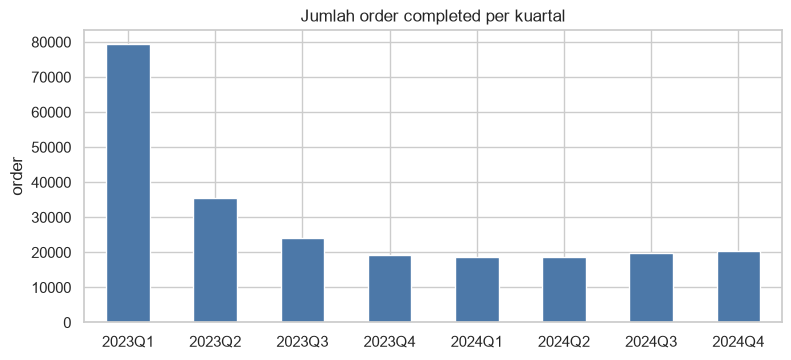

order_date
2023Q1    79487
2023Q2    35539
2023Q3    24095
2023Q4    19296
2024Q1    18813
2024Q2    18583
2024Q3    19901
2024Q4    20379
dtype: int64

In [48]:
oq = fact[fact["order_status"] == "completed"].groupby(fact["order_date"].dt.to_period("Q").astype(str)).size()
fig, ax = plt.subplots(figsize=(9, 3.8))
oq.plot(kind="bar", ax=ax, color="#4c78a8")
ax.set_title("Jumlah order completed per kuartal"); ax.set_xlabel(""); ax.set_ylabel("order")
plt.xticks(rotation=0); plt.show()
oq

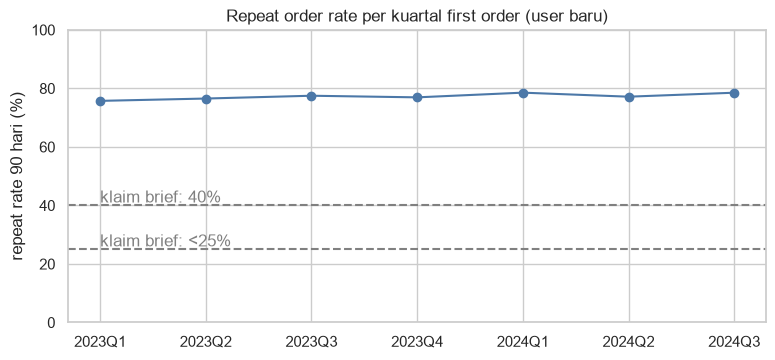

,user,repeat_rate
q,,
2023Q1,2662,0.757
2023Q2,3396,0.765
2023Q3,3514,0.775
2023Q4,3525,0.769
2024Q1,3691,0.785
2024Q2,3928,0.772
2024Q3,4181,0.785


In [49]:
trend = base.groupby("q").agg(user=("user_id", "count"), repeat_rate=("is_repeat_90d", "mean"))
trend = trend[trend["user"] > 100]       # 2024Q4 hanya berisi 41 user eligible, dibuang dari grafik

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(trend.index, trend["repeat_rate"] * 100, marker="o", color="#4c78a8")
ax.axhline(40, ls="--", color="grey"); ax.text(0, 41, "klaim brief: 40%", color="grey")
ax.axhline(25, ls="--", color="grey"); ax.text(0, 26, "klaim brief: <25%", color="grey")
ax.set_ylim(0, 100); ax.set_ylabel("repeat rate 90 hari (%)"); ax.set_title("Repeat order rate per kuartal first order (user baru)")
plt.show()
trend

In [50]:
comp = fact[(fact["order_status"] == "completed") & (fact["is_outlier_amount"] == 0)]
pi = comp.groupby(comp["order_date"].dt.to_period("Q").astype(str)).agg(
    promo_cost=("promo_cost", "sum"), gmv=("total_amount", "sum"), orders=("order_id", "count"))
pi["promo_intensity_%"] = pi["promo_cost"] / pi["gmv"] * 100
pi["promo_cost_per_order"] = pi["promo_cost"] / pi["orders"]
pi[["orders", "promo_intensity_%", "promo_cost_per_order"]].round(2)

,orders,promo_intensity_%,promo_cost_per_order
order_date,,,
2023Q1,78629,6.200,60678.480
2023Q2,35123,6.400,62564.910
2023Q3,23820,6.030,60672.320
2023Q4,19063,6.370,62934.980
2024Q1,18587,6.170,60863.450
2024Q2,18363,6.580,64445.210
2024Q3,19683,6.230,62721.370
2024Q4,20128,6.360,61354.610


Beberapa temuan penting dari baseline:

* **Lonjakan Q1 2023 adalah artefak data.** Ada 79 ribu order `completed` di Q1 2023, sedangkan kuartal lain hanya sekitar 18-36 ribu. Penyebabnya, 22 ribu user yang mendaftar sebelum 2023 muncul pertama kali di data pada kuartal itu. Itu alasan kita memakai user baru saja.
* **Repeat rate user baru stabil di sekitar 77%** (kisaran 75,7% sampai 78,5% per kuartal), tidak menurun. Angka ini juga **jauh lebih tinggi dari klaim brief** (turun dari 40% ke di bawah 25%). Kita tidak bisa mereproduksi penurunan itu dengan definisi yang kita pakai. Kemungkinan penyebabnya: brief memakai definisi atau basis yang berbeda, atau datanya memang tidak memuat sinyal tersebut. Kita laporkan apa adanya, dan tetap memakai 77% sebagai baseline internal data ini.
* **Intensitas promo juga stabil**: sekitar 6,0%-6,6% dari GMV, atau Rp60-64 ribu per order, di semua kuartal. CLV:CAC tidak bisa dihitung karena data CAC dan margin tidak tersedia, jadi intensitas promo kita pakai sebagai pengganti (proxy).

Karena repeat rate datar, pertanyaannya bergeser dari "mengapa turun?" menjadi **"promo dan faktor apa yang berkaitan dengan user yang kembali dan tidak kembali?"**

## Apakah promo mendorong repeat order?

Pertama, kita lihat repeat rate per kanal akuisisi, lalu berdasarkan pemakaian promo, jenis voucher, dan periode kampanye. Untuk membandingkan proporsi antar kelompok kita pakai uji *chi-square* (hipotesis nol: repeat rate sama di semua kelompok).

In [51]:
def seg(df, col, minn=0):
    t = df.groupby(col).agg(user=("user_id", "count"), repeat_rate=("is_repeat_90d", "mean"),
                            avg_promo_cost_first=("first_order_promo_cost", "mean"))
    return t[t["user"] >= minn]

ch = seg(base, "acquisition_channel")
chi2, p, _, _ = chi2_contingency(pd.crosstab(base["acquisition_channel"], base["is_repeat_90d"]))
print(f"Uji chi-square repeat vs kanal: p-value = {p:.4f}")
ch

Uji chi-square repeat vs kanal: p-value = 0.0025


,user,repeat_rate,avg_promo_cost_first
acquisition_channel,,,
ads,7550,0.788,65061.363
affiliate,2515,0.773,62611.750
organic,11152,0.766,62645.381
referral,3721,0.767,70505.747


In [52]:
res = {}
for col, label in [("first_order_has_promo", "pakai promo vs tidak"),
                   ("first_order_voucher_type", "jenis voucher"),
                   ("first_order_in_campaign", "order di periode kampanye")]:
    chi2, p, _, _ = chi2_contingency(pd.crosstab(base[col], base["is_repeat_90d"]))
    res[label] = p
print("p-value chi-square (repeat vs ...):")
print(pd.Series(res).apply(lambda x: f"{x:.4f}").to_string())
display(seg(base, "first_order_voucher_type"))
seg(base, "first_order_in_campaign")

p-value chi-square (repeat vs ...):
pakai promo vs tidak         0.6904
jenis voucher                0.5734
order di periode kampanye    0.0000


,user,repeat_rate,avg_promo_cost_first
first_order_voucher_type,,,
No Voucher,10411,0.775,7799.937
cashback,4449,0.769,110158.322
diskon_persen,4302,0.768,118129.340
free_ongkir,5776,0.778,91787.236


,user,repeat_rate,avg_promo_cost_first
first_order_in_campaign,,,
0,14485,0.784,60178.779
1,10453,0.759,70598.432


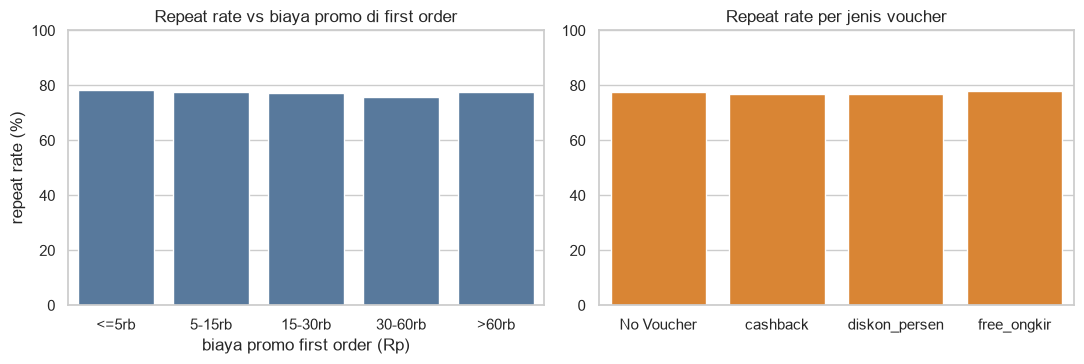

,user,repeat_rate,avg_promo_cost_first
promo_bucket,,,
<=5rb,4053,0.783,2559.105
5-15rb,7827,0.777,9716.712
15-30rb,6502,0.773,21414.744
30-60rb,4303,0.759,40931.480
>60rb,2253,0.775,536113.375


In [53]:
base["promo_bucket"] = pd.cut(base["first_order_promo_cost"], [-1, 5000, 15000, 30000, 60000, 1e9],
                              labels=["<=5rb", "5-15rb", "15-30rb", "30-60rb", ">60rb"])
pb = seg(base, "promo_bucket")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.barplot(x=pb.index, y=pb["repeat_rate"] * 100, ax=axes[0], color="#4c78a8")
axes[0].set_ylim(0, 100); axes[0].set_title("Repeat rate vs biaya promo di first order"); axes[0].set_ylabel("repeat rate (%)"); axes[0].set_xlabel("biaya promo first order (Rp)")
vt = seg(base, "first_order_voucher_type")
sns.barplot(x=vt.index, y=vt["repeat_rate"] * 100, ax=axes[1], color="#f58518")
axes[1].set_ylim(0, 100); axes[1].set_title("Repeat rate per jenis voucher"); axes[1].set_ylabel(""); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()
pb

Dari hasil di atas, kita bisa menjawab pertanyaan pertama:

* **Antar kanal akuisisi**, perbedaannya statistik signifikan (p = 0,0025) tetapi kecil: kanal ads tertinggi (78,8%) dan organic terendah (76,6%), selisih hanya sekitar 2 poin persentase.
* **Pakai promo vs tanpa promo**: repeat rate hampir identik (77,3% vs 77,5%, p = 0,69). Jenis voucher (cashback, diskon persen, free ongkir) juga tidak berbeda (p = 0,57).
* **Besar promo**: repeat rate datar di semua tingkat biaya promo, dari promo ≤ Rp5 ribu sampai > Rp60 ribu (kisaran 76%-78%). Promo yang lebih besar tidak membuat user lebih mungkin kembali.
* **Periode kampanye** justru sedikit negatif: user yang first order-nya di periode kampanye repeat rate-nya 75,9%, dibanding 78,4% di luar kampanye (p < 0,001), sementara biaya promo per order lebih tinggi (sekitar Rp70,6 ribu vs Rp60,2 ribu).

Artinya, pada data ini **promo di first order tidak berkaitan dengan peluang user kembali**.

## Segmen mana yang menyerap promo terbanyak tetapi kurang menghasilkan repeat?

Kita gabungkan kanal akuisisi, jenis voucher, dan periode kampanye menjadi segmen, lalu hitung berapa porsi budget promo yang diserap dan berapa **biaya promo per user yang akhirnya repeat** (semakin tinggi, semakin tidak efisien).

In [54]:
seg_cols = ["acquisition_channel", "first_order_voucher_type", "first_order_in_campaign"]
a = base[base["first_order_has_promo"] == 1].groupby(seg_cols).agg(
    user=("user_id", "count"), repeat_rate=("is_repeat_90d", "mean"),
    total_promo_cost=("first_order_promo_cost", "sum"), repeat_users=("is_repeat_90d", "sum"))
a["promo_cost_per_repeat_user"] = a["total_promo_cost"] / a["repeat_users"]
a["share_of_promo_budget_%"] = a["total_promo_cost"] / a["total_promo_cost"].sum() * 100
overall = base["is_repeat_90d"].mean()
a["repeat_vs_avg_pp"] = (a["repeat_rate"] - overall) * 100
a = a[a["user"] >= 200]
cols_show = ["user", "repeat_rate", "total_promo_cost", "share_of_promo_budget_%", "promo_cost_per_repeat_user", "repeat_vs_avg_pp"]
a[cols_show].sort_values("total_promo_cost", ascending=False).head(8).round(3)

user  \
acquisition_channel first_order_voucher_type first_order_in_campaign         
organic             free_ongkir              0                        1481   
                    cashback                 0                        1159   
                    free_ongkir              1                        1116   
                    diskon_persen            0                        1088   
                    cashback                 1                         815   
                    diskon_persen            1                         795   
ads                 diskon_persen            0                         774   
                    cashback                 0                         816   

                                                                      repeat_rate  \
acquisition_channel first_order_voucher_type first_order_in_campaign                
organic             free_ongkir              0                              0.774   
                    cashback                 0                              0.771   
                    free_ongkir              1                              0.752   
                    diskon_persen            0                              0.769   
                    cashback                 1                              0.745   
                    diskon_persen            1                              0.752   
ads                 diskon_persen            0                              0.796   
                    cashback                 0                              0.782   

                                                                      total_promo_cost  \
acquisition_channel first_order_voucher_type first_order_in_campaign                     
organic             free_ongkir              0                               128060104   
                    cashback                 0                               115150150   
                    free_ongkir              1                               110940288   
                    diskon_persen            0                               108326794   
                    cashback                 1                               104209744   
                    diskon_persen            1                                94940901   
ads                 diskon_persen            0                                86575879   
                    cashback                 0                                85121809   

                                                                      share_of_promo_budget_%  \
acquisition_channel first_order_voucher_type first_order_in_campaign                            
organic             free_ongkir              0                                          8.378   
                    cashback                 0                                          7.534   
                    free_ongkir              1                                          7.258   
                    diskon_persen            0                                          7.087   
                    cashback                 1                                          6.818   
                    diskon_persen            1                                          6.212   
ads                 diskon_persen            0                                          5.664   
                    cashback                 0                                          5.569   

                                                                      promo_cost_per_repeat_user  \
acquisition_channel first_order_voucher_type first_order_in_campaign                               
organic             free_ongkir              0                                        111745.291   
                    cashback                 0                                        128803.300   
                    free_ongkir              1                                        132229.187   
                    diskon_persen            0                    

In [55]:
big = a[a["total_promo_cost"] >= a["total_promo_cost"].median()]
big[big["repeat_rate"] < overall][cols_show].sort_values("promo_cost_per_repeat_user", ascending=False).head(6).round(3)

user  \
acquisition_channel first_order_voucher_type first_order_in_campaign         
organic             cashback                 1                         815   
                    diskon_persen            1                         795   
                    free_ongkir              1                        1116   
ads                 free_ongkir              1                         732   
organic             diskon_persen            0                        1088   
                    cashback                 0                        1159   

                                                                      repeat_rate  \
acquisition_channel first_order_voucher_type first_order_in_campaign                
organic             cashback                 1                              0.745   
                    diskon_persen            1                              0.752   
                    free_ongkir              1                              0.752   
ads                 free_ongkir              1                              0.761   
organic             diskon_persen            0                              0.769   
                    cashback                 0                              0.771   

                                                                      total_promo_cost  \
acquisition_channel first_order_voucher_type first_order_in_campaign                     
organic             cashback                 1                               104209744   
                    diskon_persen            1                                94940901   
                    free_ongkir              1                               110940288   
ads                 free_ongkir              1                                73003201   
organic             diskon_persen            0                               108326794   
                    cashback                 0                               115150150   

                                                                      share_of_promo_budget_%  \
acquisition_channel first_order_voucher_type first_order_in_campaign                            
organic             cashback                 1                                          6.818   
                    diskon_persen            1                                          6.212   
                    free_ongkir              1                                          7.258   
ads                 free_ongkir              1                                          4.776   
organic             diskon_persen            0                                          7.087   
                    cashback                 0                                          7.534   

                                                                      promo_cost_per_repeat_user  \
acquisition_channel first_order_voucher_type first_order_in_campaign                               
organic             cashback                 1                                        171679.974   
                    diskon_persen            1                                        158764.048   
                    free_ongkir              1                                        132229.187   
ads                 free_ongkir              1                                        131064.993   
organic             diskon_persen            0                                        129422.693   
                    cashback                 0                                        128803.300   

                                                                      repeat_vs_avg_pp  
acquisition_channel first_order_voucher_type first_order_in_campaign                    
organic             cashback                 1                                  -2.877  
                    diskon_persen            1                                  -2.136  
                    free_ongkir              1                                  -2.177  
ads                 

In [56]:
fo = base[base["first_order_has_promo"] == 1]
total_first_promo = fo["first_order_promo_cost"].sum()
spent_on_nonrepeat = fo.loc[fo["is_repeat_90d"] == 0, "first_order_promo_cost"].sum()
print(f"Total biaya promo di first order (user baru) : Rp{total_first_promo:,.0f}")
print(f"  - dihabiskan pada user yang TIDAK repeat   : Rp{spent_on_nonrepeat:,.0f} ({spent_on_nonrepeat/total_first_promo:.1%})")
print(f"  - porsi user yang tidak repeat             : {(fo['is_repeat_90d'] == 0).mean():.1%}")
by_type = fo.groupby("first_order_voucher_type").agg(total_promo=("first_order_promo_cost", "sum"), avg_promo=("first_order_promo_cost", "mean"),
                                                    repeat_rate=("is_repeat_90d", "mean"))
by_type["share_%"] = by_type["total_promo"] / by_type["total_promo"].sum() * 100
by_type.round(3)

Total biaya promo di first order (user baru) : Rp1,528,449,870
  - dihabiskan pada user yang TIDAK repeat   : Rp349,546,219 (22.9%)
  - porsi user yang tidak repeat             : 22.7%


,total_promo,avg_promo,repeat_rate,share_%
first_order_voucher_type,,,,
cashback,490094373,110158.322,0.769,32.065
diskon_persen,508192421,118129.340,0.768,33.249
free_ongkir,530163076,91787.236,0.778,34.686


Temuan untuk pertanyaan kedua:

* Budget promo tersebar **merata**: tidak ada satu segmen pun yang menyerap lebih dari sekitar 8,4% total budget, dan 22,9% biaya promo first order habis pada user yang tidak kembali, hampir sama dengan porsi user yang tidak kembali (22,7%). Ini tanda promo tidak diarahkan ke user yang lebih mungkin bertahan.
* Segmen yang paling tidak efisien adalah **organic yang first order-nya memakai cashback atau diskon persen di periode kampanye**: repeat rate sekitar 74,5%-75,2% (di bawah rata-rata 77,4%) dan biaya promo per user repeat tertinggi (sekitar Rp159-172 ribu, dibanding Rp112 ribu pada segmen organic free ongkir di luar kampanye).
* Cashback dan diskon persen menyerap sekitar **Rp998 juta (65%)** dari total biaya promo first order user baru (Rp1,53 miliar), tetapi repeat rate-nya tidak lebih tinggi dari free ongkir (76,8%-76,9% vs 77,8%) yang biayanya per order lebih rendah.

## Apakah pola promo user yang churn berbeda dari yang bertahan?

Kita definisikan *churn* sebagai user yang tidak melakukan order kedua dalam 90 hari, dan bandingkan pemakaian promo di order pertama kedua kelompok. Karena jumlah datanya besar, uji statistik bisa menganggap perbedaan yang sangat kecil sebagai signifikan, jadi kita juga perhatikan **besar** selisihnya.

In [57]:
base["status"] = np.where(base["is_repeat_90d"] == 1, "Retained (repeat)", "Churn (tidak repeat)")
cmp = base.groupby("status").agg(
    user=("user_id", "count"),
    pakai_promo_pct=("first_order_has_promo", lambda s: s.mean() * 100),
    kampanye_pct=("first_order_in_campaign", lambda s: s.mean() * 100),
    avg_promo_cost=("first_order_promo_cost", "mean"),
    median_promo_cost=("first_order_promo_cost", "median"),
    median_first_amount=("first_order_amount", "median"))
print("Uji Mann-Whitney biaya promo first order (churn vs retained): p =",
      f"{mannwhitneyu(base.loc[base.is_repeat_90d==0, 'first_order_promo_cost'], base.loc[base.is_repeat_90d==1, 'first_order_promo_cost']).pvalue:.4f}")
cmp.round(2)

Uji Mann-Whitney biaya promo first order (churn vs retained): p = 0.0176


,user,pakai_promo_pct,kampanye_pct,avg_promo_cost,median_promo_cost,median_first_amount
status,,,,,,
Churn (tidak repeat),5647,58.490,44.700,65251.280,16487.000,363658.000
Retained (repeat),19291,58.180,41.100,64339.900,15812.000,358174.000


Pola promo user churn dan yang bertahan **nyaris sama**:

* Persentase yang memakai promo di first order: 58,5% (churn) vs 58,2% (retained).
* Median biaya promo: Rp16,5 ribu vs Rp15,8 ribu. Uji Mann-Whitney menunjukkan perbedaan yang terdeteksi secara statistik (p = 0,018) karena datanya besar, tetapi selisih rata-ratanya hanya sekitar Rp900 (sekitar 1,4%), jadi secara praktis dapat diabaikan.
* Nilai first order (median) juga mirip: sekitar Rp364 ribu vs Rp358 ribu.
* Satu-satunya selisih yang agak terlihat adalah porsi order saat kampanye: 44,7% (churn) vs 41,1% (retained), konsisten dengan temuan sebelumnya.

Jadi, **promo tidak membedakan user yang kembali dari yang tidak**. Untuk menemukan apa yang membedakan mereka, kita lihat faktor di luar promo.

## Faktor lain di luar promo: pengalaman pada order pertama

Brief meminta kita mempertimbangkan faktor di luar promo, dan Operations melaporkan kenaikan komplain pasca-pembelian. Karena itu kita periksa karakteristik **order pertama** yang berkaitan dengan pengalaman pasca-pembelian: apakah pengirimannya terlambat melewati SLA, apakah gagal, dan apakah user membuat tiket komplain.

In [58]:
tests = {}
for col, label in [("first_order_is_late", "terlambat (lewat SLA)"), ("first_order_has_ticket", "punya tiket komplain"),
                   ("first_order_zone", "zona pengiriman"), ("first_order_payment", "metode bayar")]:
    d = base.dropna(subset=[col])
    tests[label] = chi2_contingency(pd.crosstab(d[col], d["is_repeat_90d"]))[1]
print("p-value chi-square (repeat vs ...):"); print(pd.Series(tests).apply(lambda x: f"{x:.2e}").to_string())

x = base.dropna(subset=["first_order_is_late"])
display(seg(x, "first_order_is_late").rename(index={0.0: "tepat waktu", 1.0: "terlambat"}))
seg(base, "first_order_has_ticket").rename(index={0: "tanpa tiket", 1: "ada tiket"})

p-value chi-square (repeat vs ...):
terlambat (lewat SLA)    2.37e-107
punya tiket komplain     4.97e-219
zona pengiriman           7.52e-27
metode bayar              1.34e-03


,user,repeat_rate,avg_promo_cost_first
first_order_is_late,,,
tepat waktu,15797,0.817,64545.889
terlambat,8643,0.693,63579.247


,user,repeat_rate,avg_promo_cost_first
first_order_has_ticket,,,
tanpa tiket,21867,0.805,64348.037
ada tiket,3071,0.550,65957.825


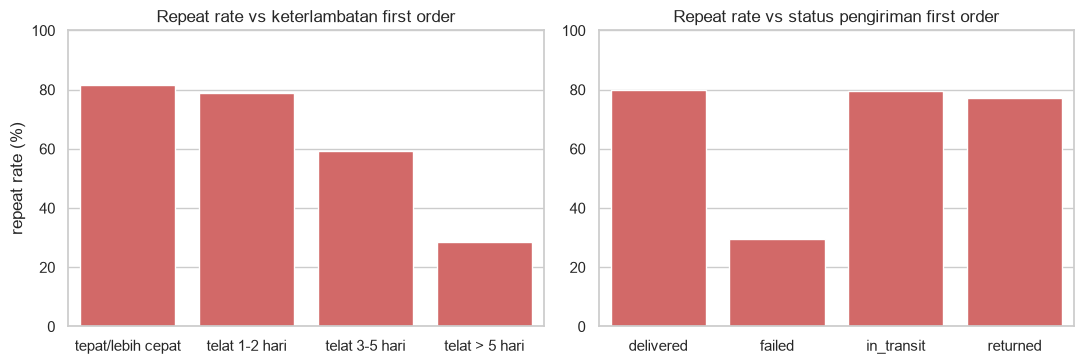

,user,repeat_rate,avg_promo_cost_first
delay_bucket,,,
tepat/lebih cepat,15797,0.817,64545.889
telat 1-2 hari,6927,0.789,63057.169
telat 3-5 hari,123,0.593,97219.423
telat > 5 hari,1593,0.287,63251.996


,user,repeat_rate,avg_promo_cost_first
first_order_delivery_status,,,
delivered,22630,0.798,64140.990
failed,1156,0.297,62916.228
in_transit,496,0.794,81526.944
returned,654,0.771,68662.174


In [59]:
base["delay_bucket"] = pd.cut(base["first_order_delay_days"], [-30, 0, 2, 5, 30],
                              labels=["tepat/lebih cepat", "telat 1-2 hari", "telat 3-5 hari", "telat > 5 hari"])
db = seg(base.dropna(subset=["delay_bucket"]), "delay_bucket")
ds = seg(base, "first_order_delivery_status", minn=100)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.barplot(x=db.index.astype(str), y=db["repeat_rate"] * 100, ax=axes[0], color="#e45756")
axes[0].set_ylim(0, 100); axes[0].set_title("Repeat rate vs keterlambatan first order"); axes[0].set_ylabel("repeat rate (%)"); axes[0].set_xlabel("")
sns.barplot(x=ds.index, y=ds["repeat_rate"] * 100, ax=axes[1], color="#e45756")
axes[1].set_ylim(0, 100); axes[1].set_title("Repeat rate vs status pengiriman first order"); axes[1].set_ylabel(""); axes[1].set_xlabel("")
plt.tight_layout(); plt.show()
display(db)
ds

In [60]:
cc = seg(base.assign(first_order_complaint=base["first_order_complaint"].fillna("tanpa tiket")), "first_order_complaint")
cc.sort_values("repeat_rate")

,user,repeat_rate,avg_promo_cost_first
first_order_complaint,,,
keterlambatan,1181,0.297,75856.023
kurir_kasar,318,0.692,43374.824
lainnya,310,0.700,49750.690
produk_rusak,716,0.705,67023.994
refund,546,0.725,65504.449
tanpa tiket,21867,0.805,64348.037


### Kualitas penanganan tiket per kategori

In [61]:
tq = df_t.groupby("complaint_category").agg(
    tiket=("ticket_id", "count"), rata_resolusi_jam=("resolution_time_hours", "mean"),
    rata_csat=("csat_score", "mean"), pct_belum_resolved=("resolution_status", lambda s: (s != "resolved").mean() * 100))
tq.sort_values("tiket", ascending=False).round(2)

,tiket,rata_resolusi_jam,rata_csat,pct_belum_resolved
complaint_category,,,,
keterlambatan,12060,43.380,2.250,19.950
produk_rusak,7171,16.750,3.560,19.500
refund,5678,18.220,3.560,19.480
lainnya,3416,18.760,3.560,20.140
kurir_kasar,3224,16.840,3.570,19.980


In [62]:
t = base.dropna(subset=["first_order_csat"]).copy()
t["csat"] = t["first_order_csat"].round().astype(int)
print("Repeat rate berdasarkan CSAT tiket (hanya tiket yang CSAT-nya terisi):")
t.groupby("csat").agg(user=("user_id", "count"), repeat_rate=("is_repeat_90d", "mean")).round(3)

Repeat rate berdasarkan CSAT tiket (hanya tiket yang CSAT-nya terisi):


,user,repeat_rate
csat,,
1,238,0.328
2,437,0.432
3,656,0.555
4,504,0.673
5,241,0.710


### Tingkat keterlambatan per zona

In [63]:
late_zone = fact[(fact["order_status"] == "completed") & fact["is_late"].notna()].groupby("shipping_zone")["is_late"].mean()
print("% order terlambat per zona:"); print((late_zone * 100).round(1).to_string())
display(seg(base, "first_order_zone"))
seg(base, "first_order_payment").sort_values("repeat_rate")

% order terlambat per zona:
shipping_zone
dalam_kota   33.800
luar_kota    33.600
luar_pulau   43.400


,user,repeat_rate,avg_promo_cost_first
first_order_zone,,,
dalam_kota,9904,0.787,64237.287
luar_kota,11239,0.785,64513.308
luar_pulau,3793,0.705,65466.132


,user,repeat_rate,avg_promo_cost_first
first_order_payment,,,
COD,4501,0.750,67259.393
QRIS,3485,0.765,63850.291
DANA,2015,0.775,57465.106
GoPay,4048,0.776,61139.697
Bank Transfer,4849,0.783,65772.522
ShopeePay,2238,0.783,65394.800
Credit Card,1244,0.787,70869.028
OVO,2558,0.789,65547.672


### Selisih Repeat Rate

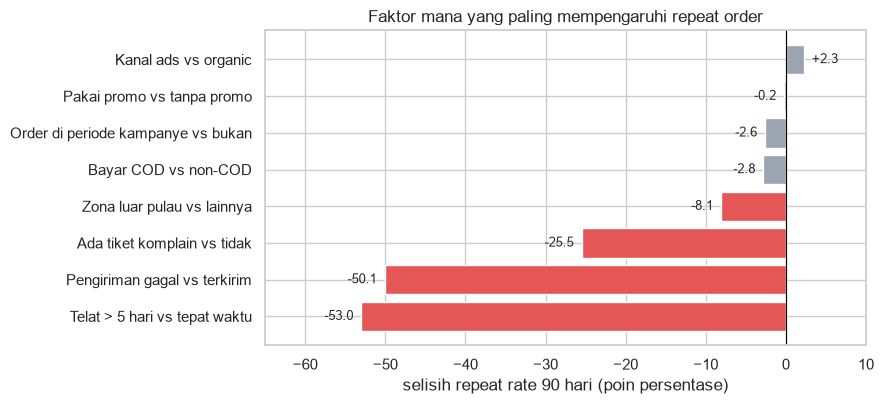

Telat > 5 hari vs tepat waktu        -53.000
Pengiriman gagal vs terkirim         -50.100
Ada tiket komplain vs tidak          -25.500
Zona luar pulau vs lainnya            -8.100
Bayar COD vs non-COD                  -2.800
Order di periode kampanye vs bukan    -2.600
Pakai promo vs tanpa promo            -0.200
Kanal ads vs organic                   2.300
dtype: float64

In [64]:
def diff_pp(mask_a, mask_b, df=base):
    return (df.loc[mask_a, "is_repeat_90d"].mean() - df.loc[mask_b, "is_repeat_90d"].mean()) * 100

b = base
drivers = pd.Series({
    "Pakai promo vs tanpa promo": diff_pp(b.first_order_has_promo == 1, b.first_order_has_promo == 0),
    "Order di periode kampanye vs bukan": diff_pp(b.first_order_in_campaign == 1, b.first_order_in_campaign == 0),
    "Kanal ads vs organic": diff_pp(b.acquisition_channel == "ads", b.acquisition_channel == "organic"),
    "Bayar COD vs non-COD": diff_pp(b.first_order_payment == "COD", b.first_order_payment != "COD"),
    "Zona luar pulau vs lainnya": diff_pp(b.first_order_zone == "luar_pulau", b.first_order_zone != "luar_pulau"),
    "Ada tiket komplain vs tidak": diff_pp(b.first_order_has_ticket == 1, b.first_order_has_ticket == 0),
    "Pengiriman gagal vs terkirim": diff_pp(b.first_order_delivery_status == "failed", b.first_order_delivery_status == "delivered"),
    "Telat > 5 hari vs tepat waktu": diff_pp(b.first_order_delay_days > 5, b.first_order_delay_days <= 0),
}).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.2))
colors = ["#e45756" if v < -5 else "#9aa5b1" for v in drivers]
ax.barh(drivers.index, drivers.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
for i, v in enumerate(drivers.values):
    ax.text(v + (1 if v >= 0 else -1), i, f"{v:+.1f}", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set_xlim(-65, 10)
ax.set_xlabel("selisih repeat rate 90 hari (poin persentase)")
ax.set_title("Faktor mana yang paling mempengaruhi repeat order")
plt.tight_layout(); plt.show()
drivers.round(1)

Inilah temuan paling kuat dari seluruh analisis (jawaban pertanyaan keempat):

* **Keterlambatan**: user yang pengirimannya terlambat repeat rate-nya 69,3% vs 81,7% pada yang tepat waktu. Keterlambatan ringan (1-2 hari) hampir tidak berpengaruh (78,9%). Yang merusak adalah **keterlambatan berat**: telat lebih dari 5 hari hanya menghasilkan repeat rate **28,7%** (1.593 user).
* **Pengiriman gagal**: repeat rate hanya **29,7%** (1.156 user), dibanding 79,8% pada pengiriman yang terkirim.
* **Tiket komplain**: user yang mengajukan tiket repeat rate-nya 55,0% vs 80,5%. Kategori **keterlambatan** adalah yang terburuk: **29,7%**, sedangkan kategori lain 69%-73%. Penanganan tiket keterlambatan juga paling buruk: rata-rata 43 jam untuk selesai (kategori lain sekitar 17-19 jam) dengan CSAT rata-rata 2,25 (kategori lain sekitar 3,56).
* **CSAT berkaitan kuat dengan retensi**: user dengan CSAT 1 repeat rate-nya 32,8%, sedangkan CSAT 5 sebesar 71,0% (hanya pada tiket yang CSAT-nya terisi, jadi ini bukan sampel acak).
* **Zona luar pulau**: repeat rate 70,5% vs sekitar 78,6% di zona lain. Zona ini juga punya tingkat keterlambatan lebih tinggi (sekitar 43% order terlambat vs sekitar 34% di zona lain).
* **COD**: sedikit lebih rendah (75,0%) dibanding metode lain (76,5%-78,9%), selisih kecil.

Grafik ringkasan di atas menunjukkan skala perbandingannya: promo dan kanal hanya bergeser sekitar ±2 poin, sementara keterlambatan berat dan pengiriman gagal bergeser lebih dari **50 poin**.

In [65]:
# Kontrol: apakah promo punya efek jika kita bandingkan user dengan pengalaman pengiriman yang sama?
base["severe_issue"] = ((base["first_order_delay_days"] > 5) | (base["first_order_delivery_status"] == "failed")
                        | (base["first_order_complaint"] == "keterlambatan")).astype(int)
ctrl = base.pivot_table(index="severe_issue", columns="first_order_has_promo", values="is_repeat_90d", aggfunc=["mean", "count"])
ctrl.index = ["tanpa masalah pengiriman berat", "ada masalah pengiriman berat"]
ctrl.columns = [f"{a} | {'promo' if b == 1 else 'tanpa promo'}" for a, b in ctrl.columns]
print(f"Masalah pengiriman berat = telat > 5 hari ATAU pengiriman gagal ATAU tiket 'keterlambatan': {base['severe_issue'].sum():,} user ({base['severe_issue'].mean():.1%})")
for k, lab in [(0, "tanpa masalah berat"), (1, "dengan masalah berat")]:
    d = base[base["severe_issue"] == k]
    print(f"Promo vs tanpa promo pada kelompok {lab}: p chi-square = {chi2_contingency(pd.crosstab(d['first_order_has_promo'], d['is_repeat_90d']))[1]:.3f}")
ctrl.round(3)

Masalah pengiriman berat = telat > 5 hari ATAU pengiriman gagal ATAU tiket 'keterlambatan': 3,000 user (12.0%)
Promo vs tanpa promo pada kelompok tanpa masalah berat: p chi-square = 0.489
Promo vs tanpa promo pada kelompok dengan masalah berat: p chi-square = 0.052


,mean | tanpa promo,mean | promo,count | tanpa promo,count | promo
tanpa masalah pengiriman berat,0.841,0.838,9193,12745
ada masalah pengiriman berat,0.275,0.309,1218,1782


### Apakah ini hanya kebetulan karena promo?

Untuk memastikan, kita bandingkan efek promo **di dalam kelompok yang pengalamannya sama**. Hasilnya:

* Pada user **tanpa masalah pengiriman berat** (88% user), repeat rate sekitar 84% baik dengan maupun tanpa promo (p = 0,49). Promo tidak menambah apa pun.
* Pada user **dengan masalah pengiriman berat** (12% user, 3.000 orang), repeat rate hanya 27,5% tanpa promo dan 30,9% dengan promo. Promo mungkin sedikit membantu (selisih sekitar 3 poin, p = 0,052, belum signifikan pada taraf 5%), tetapi jauh dari menutup selisih sekitar 54 poin terhadap kelompok tanpa masalah.

Jadi pengalaman pengiriman pertama lebih menentukan dibanding promo.

## Berapa *revenue at risk* dan potensi dampaknya?

Kita hitung berapa user yang "hilang" karena masalah pengiriman berat dibanding jika mereka seperti user tanpa masalah, lalu kita kalikan dengan nilai belanja lanjutan user yang repeat. Asumsi: user yang hilang akan berperilaku seperti user repeat pada umumnya (median GMV order lanjutan). Angkanya adalah **GMV, bukan laba**, dan berupa estimasi kasar.

In [66]:
ok = base[base["severe_issue"] == 0]
bad = base[base["severe_issue"] == 1]
rr_ok, rr_bad = ok["is_repeat_90d"].mean(), bad["is_repeat_90d"].mean()
gap_users = len(bad) * (rr_ok - rr_bad)

rep = base[base["is_repeat_90d"] == 1]
value_per_repeat_user = (rep["total_gmv_ex_outlier"] - rep["first_order_amount"].where(rep["first_order_is_outlier"] == 0, 0)).median()

print(f"Repeat rate tanpa masalah pengiriman berat : {rr_ok:.1%}")
print(f"Repeat rate dengan masalah pengiriman berat: { rr_bad:.1%}")
print(f"Selisih user 'hilang' (2023-2024)           : {gap_users:,.0f} user dari {len(bad):,}")
print(f"Median GMV order lanjutan per user repeat   : Rp{value_per_repeat_user:,.0f}")
print(f"Revenue at risk (GMV, 2023-2024)            : Rp{gap_users * value_per_repeat_user:,.0f}")

Repeat rate tanpa masalah pengiriman berat : 83.9%
Repeat rate dengan masalah pengiriman berat: 29.5%
Selisih user 'hilang' (2023-2024)           : 1,632 user dari 3,000
Median GMV order lanjutan per user repeat   : Rp2,372,659
Revenue at risk (GMV, 2023-2024)            : Rp3,872,185,328


In [67]:
scen = pd.DataFrame({"skenario pemulihan": ["25%", "50%", "75%", "100%"], "faktor": [.25, .5, .75, 1.0]})
scen["user kembali"] = (gap_users * scen["faktor"]).round(0)
scen["tambahan GMV (Rp)"] = scen["user kembali"] * value_per_repeat_user
scen["repeat rate baru (%)"] = (base["is_repeat_90d"].sum() + scen["user kembali"]) / len(base) * 100
scen.drop(columns="faktor").round(1)

,skenario pemulihan,user kembali,tambahan GMV (Rp),repeat rate baru (%)
0,25%,408.000,968044872.000,79.000
1,50%,816.000,1936089744.000,80.600
2,75%,1224.000,2904134616.000,82.300
3,100%,1632.000,3872179488.000,83.900


### Skenario penghematan promo

In [68]:
big_promo = fo[fo["first_order_voucher_type"].isin(["cashback", "diskon_persen"])]
sv = pd.DataFrame({"pemangkasan": ["10%", "20%", "30%"], "f": [.1, .2, .3]})
sv["hemat (Rp)"] = big_promo["first_order_promo_cost"].sum() * sv["f"]
print(f"Biaya cashback + diskon persen di first order user baru: Rp{big_promo['first_order_promo_cost'].sum():,.0f}")
sv.drop(columns="f")

Biaya cashback + diskon persen di first order user baru: Rp998,286,794


,pemangkasan,hemat (Rp)
0,10%,99828679.400
1,20%,199657358.800
2,30%,299486038.200


Hasilnya:

* Dari 3.000 user baru dengan masalah pengiriman berat di order pertama, sekitar **1.632 user "hilang"** dibanding kondisi bila mereka kembali seperti user tanpa masalah (repeat rate 29,5% vs 83,9%).
* Dengan median GMV order lanjutan sekitar Rp2,37 juta per user repeat, **revenue at risk sekitar Rp3,9 miliar GMV** selama 2023-2024. Sebagai pembanding, seluruh biaya promo first order user baru hanya sekitar Rp1,5 miliar.
* Bila hanya 25% selisih itu berhasil dipulihkan: sekitar 408 user kembali, tambahan GMV sekitar Rp968 juta, dan repeat rate keseluruhan naik dari 77,4% menjadi sekitar 79,0%.
* Di sisi lain, memangkas 20%-30% cashback dan diskon persen di first order berpotensi menghemat Rp200-300 juta selama periode data (sekitar Rp100-150 juta per tahun), **dengan asumsi repeat rate tidak berubah**. Asumsi ini hanya bisa dipastikan lewat uji coba terkontrol (A/B test), karena data kita observasional.

In [69]:
os.makedirs("tableau_output", exist_ok=True)
fact.to_csv("tableau_output/fact_orders.csv", index=False, date_format="%Y-%m-%d")
cohort.to_csv("tableau_output/user_cohort.csv", index=False, date_format="%Y-%m-%d")
cleaning_summary.to_csv("tableau_output/cleaning_summary.csv", index=False)
print("Tersimpan di folder tableau_output/")

Tersimpan di folder tableau_output/


# Kesimpulan dan Rekomendasi

## Kesimpulan

Jawaban untuk pernyataan masalah: **di data ini, promo di order pertama tidak berkaitan dengan peluang user baru untuk kembali bertransaksi, sedangkan pengalaman pengiriman pada order pertama sangat menentukan.**

1. **Baseline**: repeat rate 90 hari user baru stabil sekitar 77% (75,7%-78,5% per kuartal), dan intensitas promo stabil di sekitar 6,0%-6,6% dari GMV. Penurunan repeat rate dari 40% ke di bawah 25% yang disebut di brief **tidak terlihat** pada data ini dengan definisi yang kita pakai.
2. **Promo**: pakai promo vs tidak (77,3% vs 77,5%), jenis voucher, dan besar promo tidak membedakan repeat rate. Order di periode kampanye justru sedikit lebih rendah (75,9% vs 78,4%). Perbedaan antar kanal akuisisi kecil (maksimal sekitar 2 poin).
3. **Penyerapan budget**: promo tersebar merata tanpa pembeda peluang retensi. Sekitar Rp1,53 miliar biaya promo first order user baru, 65% di antaranya (Rp998 juta) untuk cashback dan diskon persen. Segmen paling tidak efisien: user organic dengan cashback atau diskon persen di periode kampanye.
4. **Churn vs retained**: pola promo nyaris identik antara keduanya.
5. **Pembeda utama adalah pengalaman pasca-pembelian**: keterlambatan lebih dari 5 hari (repeat rate 28,7%), pengiriman gagal (29,7%), dan tiket komplain keterlambatan (29,7%), dibanding sekitar 80% pada user tanpa masalah. Pola ini tetap muncul setelah dibandingkan di dalam kelompok yang pengalamannya sama.
6. **Revenue at risk**: sekitar 12% user baru mengalami masalah pengiriman berat di order pertama; selisih retensinya setara sekitar 1.632 user dan sekitar Rp3,9 miliar GMV (2023-2024).

## Rekomendasi

Diurutkan berdasarkan prioritas dan besar dampak.

**1. Pulihkan user baru yang order pertamanya bermasalah (prioritas tertinggi)**
* Deteksi otomatis order pertama yang terlambat melewati SLA + 2 hari, gagal terkirim, atau memicu tiket keterlambatan, lalu tangani dalam 24 jam (notifikasi proaktif, prioritas penanganan tiket, voucher pemulihan yang ditargetkan ke kelompok ini saja).
* Target: waktu penyelesaian tiket keterlambatan dari rata-rata 43 jam menjadi ≤ 18 jam (setara kategori lain), dan repeat rate kelompok bermasalah dari 29,5% menjadi ≥ 45%.
* Estimasi dampak: memulihkan sekitar 25%-30% selisih berarti sekitar 410-490 user kembali, tambahan GMV sekitar Rp1,0-1,2 miliar selama periode data, dan repeat rate keseluruhan naik sekitar 1,6-2,0 poin (77,4% menjadi sekitar 79%).

**2. Realokasi cashback dan diskon persen di first order**
* Lakukan uji coba A/B: pangkas 20%-30% cashback dan diskon persen di first order untuk segmen yang paling tidak efisien (organic, periode kampanye), dengan kelompok kontrol.
* Target: hemat Rp200-300 juta selama periode data (sekitar Rp100-150 juta per tahun) dengan batas pengaman repeat rate tidak turun lebih dari 1 poin. Alihkan sebagian penghematan ke rekomendasi 1.

**3. Perbaiki layanan zona luar pulau**
* Zona ini punya tingkat keterlambatan lebih tinggi (sekitar 43% vs 34%) dan repeat rate lebih rendah (70,5% vs sekitar 78,6%). Audit performa kurir dan rute di zona ini, dan sesuaikan SLA yang dijanjikan dengan kemampuan nyata.

**4. Evaluasi kampanye WIB dan periode promo besar**
* User yang first order-nya di periode kampanye repeat rate-nya lebih rendah dan biaya promonya lebih tinggi. Ukur ROI per kampanye berdasarkan repeat rate kohort, jangan hanya jumlah transaksi.

**5. Perbaiki data dan pelacakan**
* Perbaiki di sumber: duplikat transaksi, tanggal order (1970/2030), tabrakan `order_id`, `last_active_date` yang tidak konsisten, dan nilai transaksi yang tidak wajar.
* Tambahkan data CAC dan margin agar CLV:CAC bisa dihitung langsung, bukan lewat proxy intensitas promo.

## Keterbatasan
* Analisis ini **observasional**: menunjukkan keterkaitan, bukan bukti sebab-akibat. Rekomendasi 1 dan 2 sebaiknya diuji lewat A/B test sebelum diterapkan penuh.
* Baseline repeat rate kita (sekitar 77%) berbeda jauh dari angka di brief, dan penyebabnya belum bisa dipastikan dari data ini.
* Order berstatus `completed` yang pengirimannya `failed` atau `returned` (16.852 baris) secara logika bertentangan; kita pakai status order sebagai acuan utama dan status pengiriman sebagai ukuran pengalaman user.
* Estimasi *revenue at risk* memakai asumsi median GMV order lanjutan dan merupakan GMV, bukan laba.
* CSAT hanya terisi pada sebagian tiket yang `resolved`, jadi tidak mewakili seluruh pelanggan.
